# Entrenamiento de modelos — House Pricing

Este notebook compara seis modelos de regresión, ensambles y redes neuronales para predecir `SalePrice`. Los hiperparámetros se optimizan con validación cruzada de 10 folds y el torneo se evalúa en el conjunto de validación con el RMSE real y el RMSE normalizado al rango.

**Prevención de fuga de datos y sobreajuste:**

- El pipeline de preprocesamiento se reajusta dentro de cada fold, por lo que imputación, codificación, outliers, transformación y escalado solo aprenden de las filas de entrenamiento del fold.
- Por esta razón, la validación cruzada parte de los datos sin procesar y no de `train_processed.csv`, cuya transformación se ajustó con todo el conjunto de entrenamiento.
- El conjunto de validación no participa en la búsqueda de hiperparámetros; se utiliza únicamente para evaluar los modelos finales.
- Las brechas entre entrenamiento, validación cruzada y validación permiten identificar sobreajuste.

## 1. Librerías

Importación de las librerías para manipulación de datos, modelado, validación cruzada y visualización.

In [1]:
import os

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"  # Evita un aviso informativo de MLflow al importarlo

import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import skops.io as sio
import yaml
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import (
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import ElasticNet, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold, learning_curve, train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## 2. Configuración y carga de datos

Lectura de `pipeline_config.yaml` y de los datos sin procesar. Se reproduce la división 80/20 del notebook de preprocesamiento con los mismos parámetros, de modo que el conjunto de validación es idéntico. `y` se expresa en escala logarítmica con `log1p`, como en el preprocesamiento.

In [2]:
PROJ_ROOT = Path("..")

with open(PROJ_ROOT / "pipeline_config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

TARGET = config["TARGET"]
MODEL_FEATURES = config["MODEL_FEATURES"]
RANDOM_STATE = config["SPLIT"]["RANDOM_STATE"]

raw_train = pd.read_csv(PROJ_ROOT / config["DATA"]["RAW_DIR"] / config["DATA"]["TRAIN_FILE"])

X_train, X_valid, y_train_real, y_valid_real = train_test_split(
    raw_train[MODEL_FEATURES],
    raw_train[TARGET],
    test_size=config["SPLIT"]["TEST_SIZE"],
    random_state=RANDOM_STATE,
)
y_train = np.log1p(y_train_real)
y_valid = np.log1p(y_valid_real)

print(f"X_train: {X_train.shape}")
print(f"X_valid: {X_valid.shape}")

X_train: (1168, 30)
X_valid: (292, 30)


## 3. Pipeline de preprocesamiento

Se carga el pipeline guardado y `clone` genera una copia sin ajustar, que conserva los pasos y sus parámetros pero descarta todo lo aprendido. Cada modelo se entrena dentro de un pipeline que incluye esta copia, y scikit-learn la reajusta en cada fold.

In [3]:
preprocessing = clone(joblib.load(PROJ_ROOT / config["PIPELINE_PATH"]))


def build_pipeline(model):
    """Une el preprocesamiento sin ajustar con un modelo."""
    return Pipeline([("preprocessing", clone(preprocessing)), ("model", model)])


list(preprocessing.named_steps)

['missing_indicator',
 'numeric_imputer',
 'missing_imputer',
 'frequent_imputer',
 'ordinal_encoder',
 'mean_encoder',
 'winsorizer',
 'yeo_johnson',
 'scaler']

## 4. Esquema de validación y métricas

Validación cruzada de 10 folds con mezcla de filas y semilla fija, compartida por todos los modelos. Los hiperparámetros se eligen con el RMSE en escala logarítmica. Para el torneo se calculan:

- **RMSE real:** error en dólares, después de regresar las predicciones con `np.expm1`.
- **RMSE normalizado:** RMSE real dividido entre el rango (máximo − mínimo) de `SalePrice` en entrenamiento.

In [4]:
N_FOLDS = 10
SCORING = "neg_root_mean_squared_error"

cv = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
target_range = y_train_real.max() - y_train_real.min()

print(f"Rango de SalePrice en entrenamiento: {target_range:,.0f}")

Rango de SalePrice en entrenamiento: 710,100


## 5. Modelos e hiperparámetros

Seis modelos con mallas pequeñas, de 5 a 12 configuraciones, para limitar el sobreajuste a la validación cruzada. Las configuraciones incluyen mecanismos de regularización:

- **Regresiones:** penalización L2 (`Ridge`) y L1 + L2 (`ElasticNet`).
- **Ensambles:** profundidad limitada, mínimo de observaciones por hoja y submuestreo.
- **Red neuronal:** penalización L2 y `early_stopping`, que separa una parte de cada fold de entrenamiento para detener el ajuste. El target se escala dentro del fold con `TransformedTargetRegressor`, ya que el MLP entrena mejor con valores cercanos a cero.

In [5]:
models = {
    "Ridge": {
        "model": Ridge(),
        "grid": {"model__alpha": [0.1, 1, 10, 30, 100]},
    },
    "ElasticNet": {
        "model": ElasticNet(max_iter=20_000, random_state=RANDOM_STATE),
        "grid": {
            "model__alpha": [0.0005, 0.001, 0.01],
            "model__l1_ratio": [0.2, 0.5, 0.8],
        },
    },
    "RandomForest": {
        "model": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
        "grid": {
            "model__max_depth": [10, None],
            "model__min_samples_leaf": [2, 5],
            "model__max_features": [0.2, 0.33, 0.5],
        },
    },
    "GradientBoosting": {
        "model": GradientBoostingRegressor(n_estimators=500, random_state=RANDOM_STATE),
        "grid": {
            "model__learning_rate": [0.02, 0.05],
            "model__max_depth": [2, 3, 4],
            "model__subsample": [0.7, 1.0],
        },
    },
    "HistGradientBoosting": {
        "model": HistGradientBoostingRegressor(
            max_iter=300, l2_regularization=1.0, random_state=RANDOM_STATE
        ),
        "grid": {
            "model__learning_rate": [0.03, 0.05],
            "model__max_leaf_nodes": [7, 15],
            "model__min_samples_leaf": [10, 20],
        },
    },
    "MLP": {
        "model": TransformedTargetRegressor(
            regressor=MLPRegressor(
                max_iter=2_000,
                early_stopping=True,
                n_iter_no_change=30,
                random_state=RANDOM_STATE,
            ),
            transformer=StandardScaler(),
        ),
        "grid": {
            "model__regressor__hidden_layer_sizes": [(32,), (64,), (64, 32)],
            "model__regressor__alpha": [0.01, 0.1, 1.0],
        },
    },
}

pd.DataFrame(
    {
        "modelo": list(models),
        "configuraciones": [
            int(np.prod([len(values) for values in spec["grid"].values()]))
            for spec in models.values()
        ],
    }
)

,modelo,configuraciones
0,Ridge,5
1,ElasticNet,9
2,RandomForest,12
3,GradientBoosting,12
4,HistGradientBoosting,8
5,MLP,9


## 6. Optimización de hiperparámetros

`GridSearchCV` evalúa cada configuración con los 10 folds, usando solo `X_train`. Después reentrena el mejor pipeline con todo `X_train`. El tiempo de cada búsqueda se registra para compararlo entre modelos.

In [6]:
searches = {}
training_time = {}

for name, spec in models.items():
    start = time.perf_counter()
    search = GridSearchCV(
        build_pipeline(spec["model"]),
        spec["grid"],
        cv=cv,
        scoring=SCORING,
        n_jobs=-1,
        return_train_score=True,
    )
    search.fit(X_train, y_train)

    searches[name] = search
    training_time[name] = time.perf_counter() - start
    print(f"{name}: RMSE CV (log) = {-search.best_score_:.4f} | {training_time[name]:.1f} s")

Ridge: RMSE CV (log) = 0.1290 | 13.3 s


ElasticNet: RMSE CV (log) = 0.1288 | 6.6 s


RandomForest: RMSE CV (log) = 0.1338 | 34.8 s


GradientBoosting: RMSE CV (log) = 0.1220 | 49.4 s


HistGradientBoosting: RMSE CV (log) = 0.1231 | 16.1 s


MLP: RMSE CV (log) = 0.1280 | 25.8 s


### 6.1 Mejores configuraciones

Hiperparámetros seleccionados por la validación cruzada para cada modelo.

In [7]:
best_params = pd.DataFrame(
    [
        {
            "modelo": name,
            "hiperparametros": {
                param.split("__")[-1]: value for param, value in search.best_params_.items()
            },
        }
        for name, search in searches.items()
    ]
)

with pd.option_context("display.max_colwidth", None):
    display(best_params)

,modelo,hiperparametros
0,Ridge,{'alpha': 30}
1,ElasticNet,"{'alpha': 0.01, 'l1_ratio': 0.2}"
2,RandomForest,"{'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 2}"
3,GradientBoosting,"{'learning_rate': 0.02, 'max_depth': 4, 'subsample': 0.7}"
4,HistGradientBoosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}"
5,MLP,"{'alpha': 1.0, 'hidden_layer_sizes': (64, 32)}"


## 7. Torneo en el conjunto de validación

Evaluación de los modelos finales en `X_valid`, ordenados por RMSE real de menor a mayor. Las métricas `rmse_*_log` permiten comparar las tres etapas en la misma escala:

- **`brecha_train_cv_pct`:** diferencia porcentual entre el error de validación cruzada y el de entrenamiento dentro de los folds. Una brecha alta indica sobreajuste.
- **`brecha_cv_valid_pct`:** diferencia porcentual entre el error en validación y el de validación cruzada. Una brecha alta indica que el desempeño estimado no se sostiene con datos nuevos.

In [8]:
rows = []
predictions = {}

for name, search in searches.items():
    pred_log = search.predict(X_valid)
    pred_real = np.expm1(pred_log)
    predictions[name] = pred_real

    best = search.best_index_
    rmse_train_log = -search.cv_results_["mean_train_score"][best]
    rmse_cv_log = -search.best_score_
    rmse_valid_log = mean_squared_error(y_valid, pred_log) ** 0.5
    rmse_real = mean_squared_error(y_valid_real, pred_real) ** 0.5

    rows.append(
        {
            "modelo": name,
            "rmse_real": rmse_real,
            "rmse_normalizado": rmse_real / target_range,
            "rmse_train_log": rmse_train_log,
            "rmse_cv_log": rmse_cv_log,
            "rmse_valid_log": rmse_valid_log,
            "brecha_train_cv_pct": (rmse_cv_log / rmse_train_log - 1) * 100,
            "brecha_cv_valid_pct": (rmse_valid_log / rmse_cv_log - 1) * 100,
        }
    )

tournament = pd.DataFrame(rows).sort_values("rmse_real").reset_index(drop=True)
tournament.round(4)

,modelo,rmse_real,rmse_normalizado,rmse_train_log,rmse_cv_log,rmse_valid_log,brecha_train_cv_pct,brecha_cv_valid_pct
0,GradientBoosting,26686.8387,0.0376,0.0587,0.1220,0.1367,107.8026,12.0761
1,MLP,27937.3352,0.0393,0.0971,0.1280,0.1388,31.8771,8.4396
2,RandomForest,28423.9453,0.0400,0.0663,0.1338,0.1451,101.8107,8.3937
3,HistGradientBoosting,28820.1727,0.0406,0.0562,0.1231,0.1432,118.8853,16.3610
4,Ridge,30437.6863,0.0429,0.1257,0.1290,0.1333,2.5945,3.3774
5,ElasticNet,30690.4509,0.0432,0.1258,0.1288,0.1335,2.3796,3.6480


In [9]:
print(f"Modelo con menor RMSE real: {tournament.loc[0, 'modelo']}")

Modelo con menor RMSE real: GradientBoosting


## 8. Gráficas de desempeño

Para cada modelo se presentan, en orden de posición en el torneo:

- **Real vs predicho:** valores en dólares sobre `X_valid`; los puntos cercanos a la línea diagonal indican mejores predicciones.
- **Residuales:** error (real − predicho) frente al valor predicho; un patrón definido indica un error sistemático.
- **Curva de aprendizaje:** RMSE logarítmico por tamaño de muestra, con el preprocesamiento reajustado en cada fold y solo con `X_train`. La curva inicia en el 40% de los datos porque, en muestras menores, `CategoricalImputer` puede encontrar empates en la moda y no admite ajustar el modelo. Una separación amplia entre las curvas indica sobreajuste; la convergencia indica buena generalización.

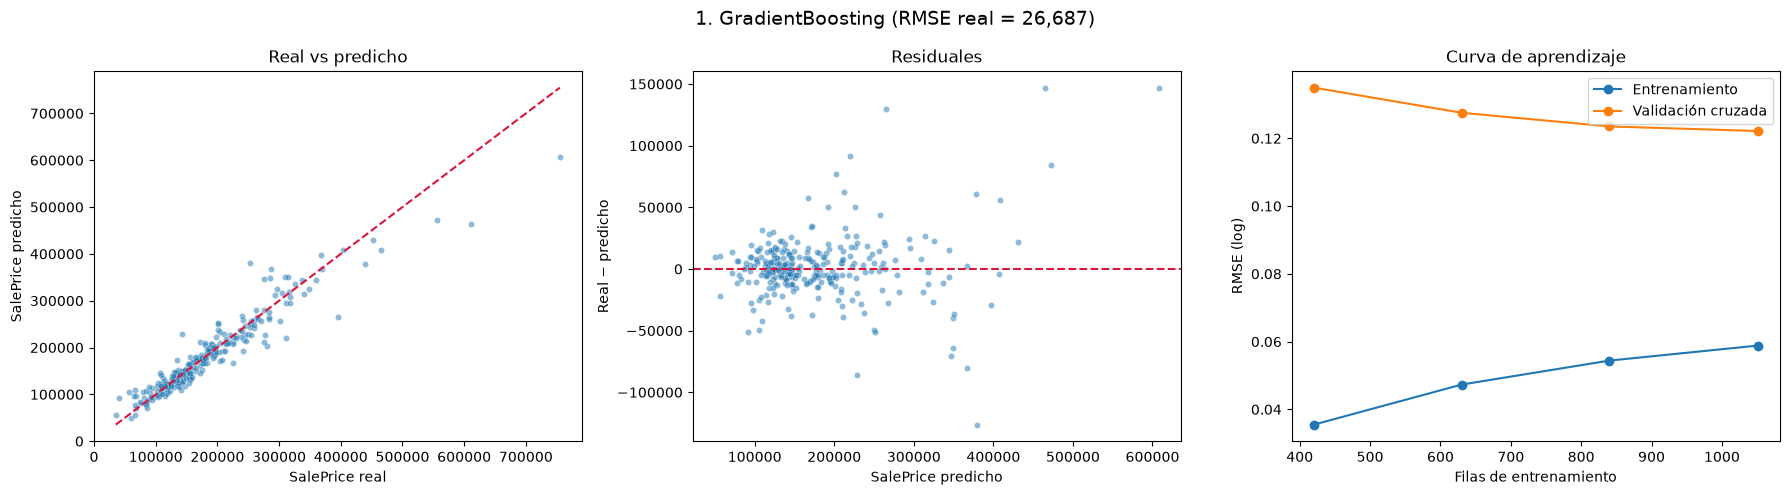

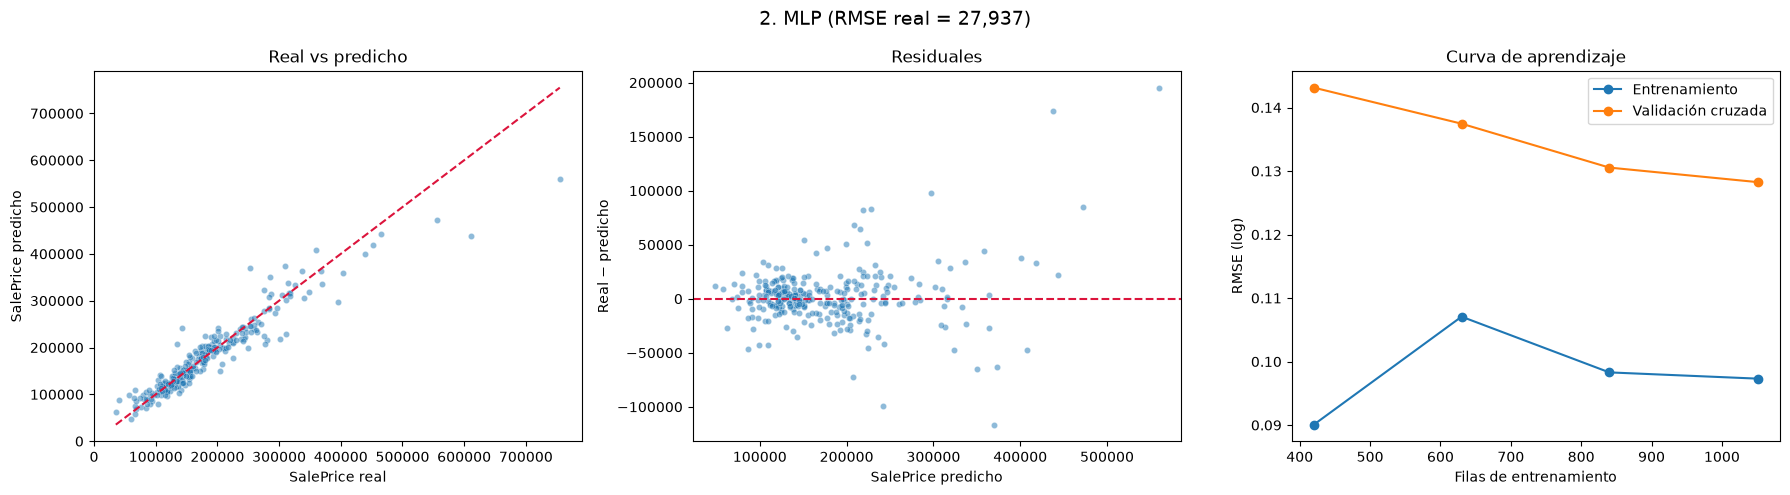

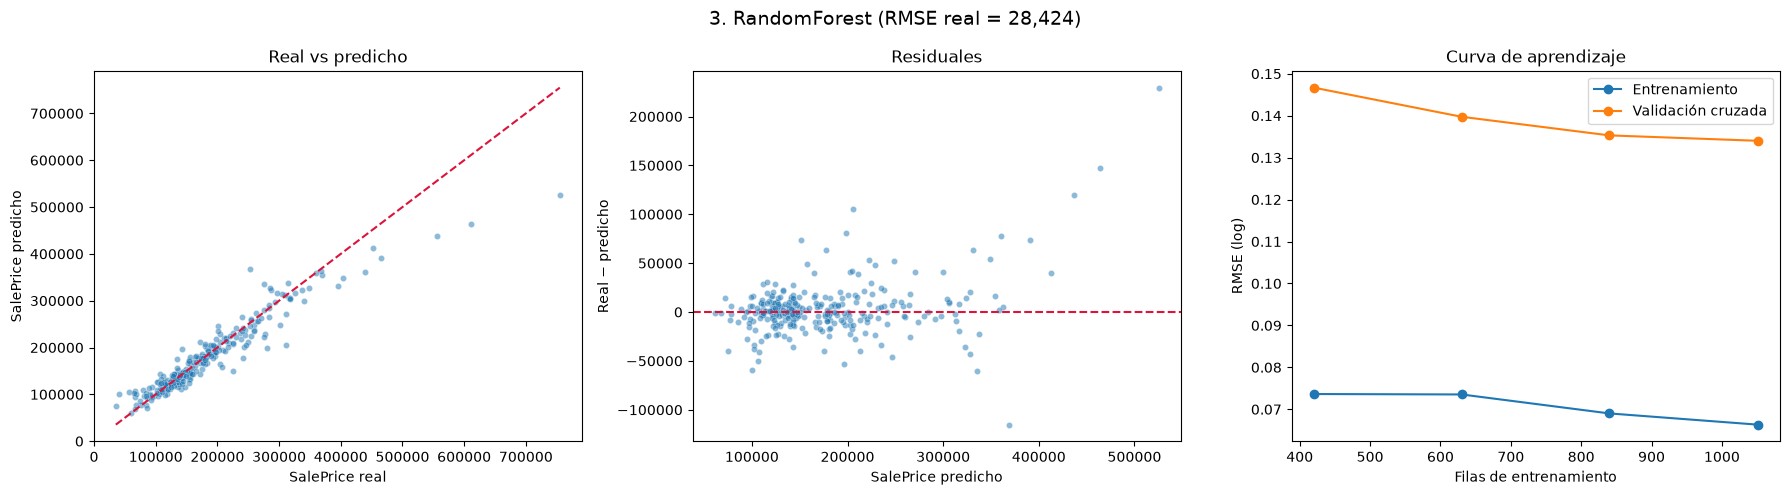

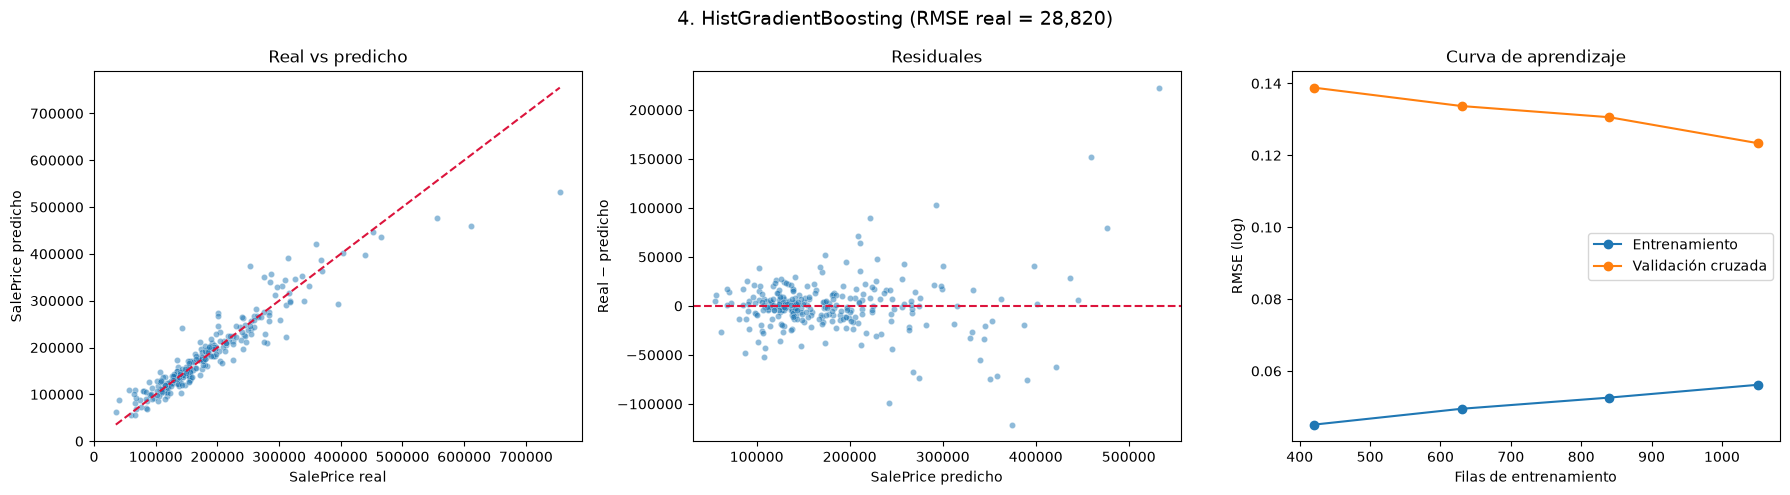

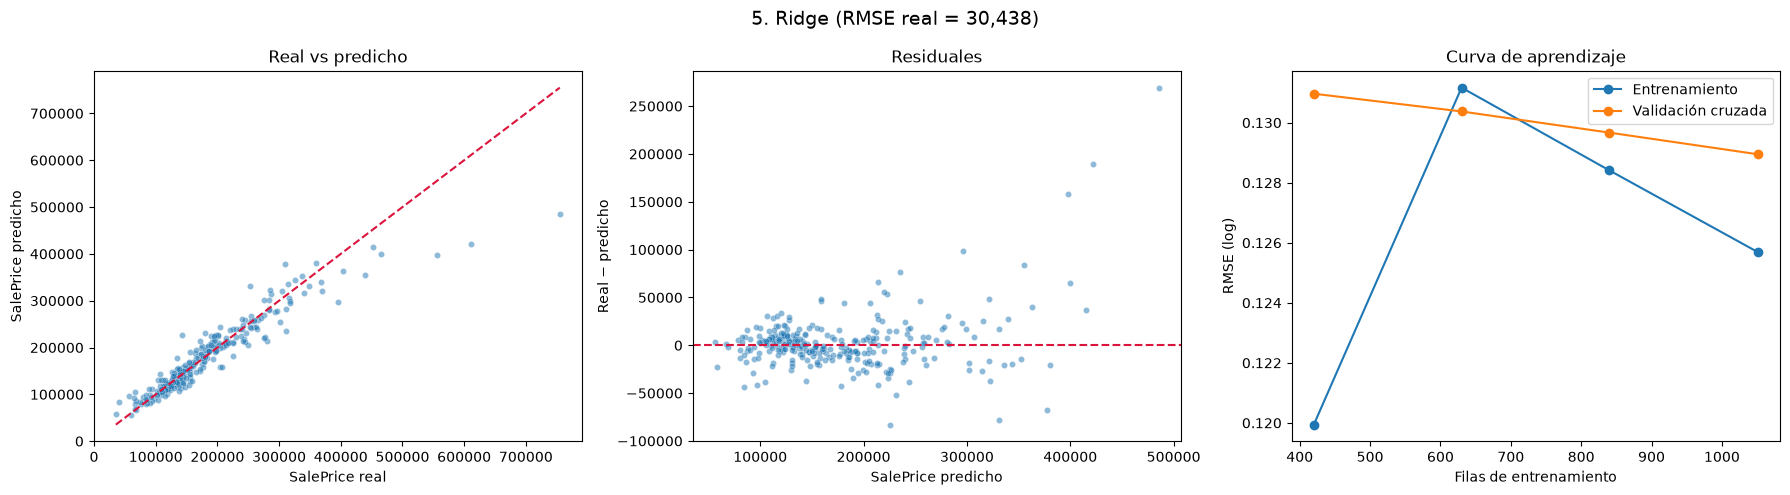

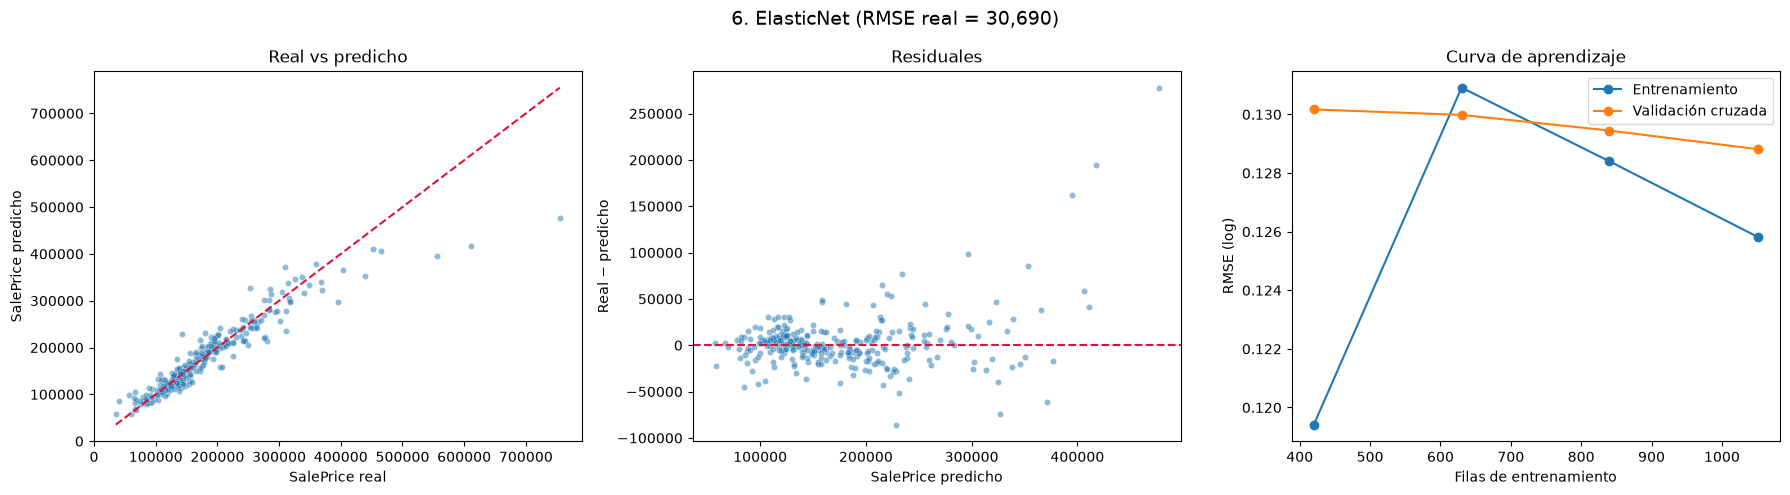

In [10]:
TRAIN_SIZES = np.linspace(0.4, 1.0, 4)
figures = {}

for rank, name in enumerate(tournament["modelo"], start=1):
    pred_real = predictions[name]
    residuals = y_valid_real - pred_real
    sizes, train_scores, cv_scores = learning_curve(
        clone(searches[name].best_estimator_),
        X_train,
        y_train,
        cv=cv,
        train_sizes=TRAIN_SIZES,
        scoring=SCORING,
        n_jobs=-1,
        error_score="raise",
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    rmse_real = tournament.loc[rank - 1, "rmse_real"]
    fig.suptitle(f"{rank}. {name} (RMSE real = {rmse_real:,.0f})", fontsize=14)

    limits = [y_valid_real.min(), y_valid_real.max()]
    sns.scatterplot(x=y_valid_real, y=pred_real, alpha=0.5, s=20, ax=axes[0])
    axes[0].plot(limits, limits, color="crimson", linestyle="--")
    axes[0].set(title="Real vs predicho", xlabel="SalePrice real", ylabel="SalePrice predicho")

    sns.scatterplot(x=pred_real, y=residuals, alpha=0.5, s=20, ax=axes[1])
    axes[1].axhline(0, color="crimson", linestyle="--")
    axes[1].set(title="Residuales", xlabel="SalePrice predicho", ylabel="Real − predicho")

    axes[2].plot(sizes, -train_scores.mean(axis=1), marker="o", label="Entrenamiento")
    axes[2].plot(sizes, -cv_scores.mean(axis=1), marker="o", label="Validación cruzada")
    axes[2].set(title="Curva de aprendizaje", xlabel="Filas de entrenamiento", ylabel="RMSE (log)")
    axes[2].legend()

    plt.tight_layout()
    figures[name] = fig
    plt.show()

## 9. Guardado del modelo ganador

Se guarda en `models/` el modelo con menor RMSE real del torneo. El archivo contiene el pipeline completo, preprocesamiento y modelo, ajustado con `X_train` (80% de los datos). Las métricas del torneo corresponden a esta versión. El modelo recibe las 30 variables sin procesar y devuelve `SalePrice` en escala logarítmica. El nombre, la ruta y el RMSE real se registran en `pipeline_config.yaml`.

In [11]:
WINNER_MODEL_PATH = "models/winner_model.joblib"

winner_name = tournament.loc[0, "modelo"]
winner_model = searches[winner_name].best_estimator_

joblib.dump(winner_model, PROJ_ROOT / WINNER_MODEL_PATH)

config["WINNER"] = {
    "NAME": winner_name,
    "MODEL_PATH": WINNER_MODEL_PATH,
    "RMSE_REAL": float(tournament.loc[0, "rmse_real"]),
}

with open(PROJ_ROOT / "pipeline_config.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

print(f"Modelo ganador guardado: {winner_name} -> {WINNER_MODEL_PATH}")

Modelo ganador guardado: GradientBoosting -> models/winner_model.joblib


## 10. Registro en MLflow

Se registra cada modelo del torneo en MLflow y los tres mejores se publican en el Model Registry. El registro se guarda localmente en `mlflow.db` y `mlartifacts/`, en la raíz del proyecto, y se consulta desde la raíz con:

```bash
python -m mlflow ui --backend-store-uri sqlite:///mlflow.db
```

### 10.1 Configuración del experimento

Se conecta MLflow a la base local y se crea el experimento de entrenamiento si no existe. Los artefactos de los runs se guardan en `mlartifacts/`.

In [12]:
MLFLOW_DB = "mlflow.db"
MLFLOW_ARTIFACTS_DIR = "mlartifacts"
TRAINING_EXPERIMENT = "house-pricing-entrenamiento"
INFERENCE_EXPERIMENT = "house-pricing-inferencia"
REGISTERED_MODEL = "house-pricing"
ROLES = ["champion", "challenger-1", "challenger-2"]

mlflow.set_tracking_uri(f"sqlite:///{(PROJ_ROOT / MLFLOW_DB).resolve().as_posix()}")
if mlflow.get_experiment_by_name(TRAINING_EXPERIMENT) is None:
    mlflow.create_experiment(
        TRAINING_EXPERIMENT,
        artifact_location=(PROJ_ROOT / MLFLOW_ARTIFACTS_DIR).resolve().as_uri(),
    )
mlflow.set_experiment(TRAINING_EXPERIMENT)
print(f"Experimento activo: {TRAINING_EXPERIMENT}")

2026/11/10 19:30:20 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/11/10 19:30:20 INFO mlflow.store.db.utils: Updating database tables


Experimento activo: house-pricing-entrenamiento


### 10.2 Runs por modelo

Se crea un run por modelo con:

- **Tags:** algoritmo, posición en el torneo y rol en el registro.
- **Parámetros:** hiperparámetros elegidos y datos del esquema de validación.
- **Métricas:** las del torneo y el tiempo de búsqueda.
- **Artefactos:** gráficas de desempeño y pipeline completo (preprocesamiento + modelo), que recibe las 30 variables crudas y devuelve `SalePrice` en escala logarítmica.

Los modelos se guardan con `skops`, que solo carga tipos declarados como confiables; se aceptan únicamente tipos de `feature-engine` y `scikit-learn`, y cualquier otro genera un error. La firma del modelo declara como decimales las columnas enteras, porque en datos nuevos pueden traer valores vacíos. Los tres primeros lugares se registran en el modelo `house-pricing`.

In [13]:
TOURNAMENT_METRICS = [
    "rmse_real",
    "rmse_normalizado",
    "rmse_train_log",
    "rmse_cv_log",
    "rmse_valid_log",
    "brecha_train_cv_pct",
    "brecha_cv_valid_pct",
]

TRUSTED_PREFIXES = ("feature_engine.", "sklearn.")


def trusted_types(model):
    """Tipos que skops debe aceptar al guardar y cargar el modelo."""
    untrusted = sio.get_untrusted_types(data=sio.dumps(model))
    unexpected = [name for name in untrusted if not name.startswith(TRUSTED_PREFIXES)]
    if unexpected:
        raise ValueError(f"Tipos no reconocidos en el modelo: {unexpected}")
    return untrusted


signature_input = X_train.astype(
    {col: "float64" for col in X_train.select_dtypes("integer").columns}
)
registered_versions = {}

for rank, row in tournament.iterrows():
    name = row["modelo"]
    search = searches[name]
    model = search.best_estimator_
    role = ROLES[rank] if rank < len(ROLES) else "ninguno"

    with mlflow.start_run(run_name=name):
        mlflow.set_tags({"algorithm": name, "tournament_rank": rank + 1, "role": role})
        mlflow.log_params(
            {param.split("__")[-1]: value for param, value in search.best_params_.items()}
        )
        mlflow.log_params(
            {
                "n_folds": N_FOLDS,
                "n_configuraciones": len(search.cv_results_["params"]),
                "filas_train": len(X_train),
                "filas_validacion": len(X_valid),
                "transformacion_target": config["TARGET_TRANSFORM"],
                "random_state": RANDOM_STATE,
            }
        )
        mlflow.log_metrics({metric: float(row[metric]) for metric in TOURNAMENT_METRICS})
        mlflow.log_metric("tiempo_busqueda_s", training_time[name])
        mlflow.log_figure(figures[name], "graficas/desempeno.png")
        model_info = mlflow.sklearn.log_model(
            model,
            name="model",
            signature=infer_signature(signature_input, search.predict(X_train)),
            input_example=signature_input.head(5),
            registered_model_name=REGISTERED_MODEL if rank < len(ROLES) else None,
            skops_trusted_types=trusted_types(model),
        )

    if rank < len(ROLES):
        registered_versions[f"{role}-{name.lower()}"] = model_info.registered_model_version

print(f"Runs registrados: {len(tournament)}")

Successfully registered model 'house-pricing'.
Created version '1' of model 'house-pricing'.


Registered model 'house-pricing' already exists. Creating a new version of this model...
Created version '2' of model 'house-pricing'.


Registered model 'house-pricing' already exists. Creating a new version of this model...
Created version '3' of model 'house-pricing'.


Runs registrados: 6


### 10.3 Champion y challengers

Se asignan alias a las versiones registradas según su posición en el torneo: el primer lugar es el champion y el segundo y tercero son challengers. Cada alias incluye el nombre del algoritmo. Antes se eliminan los alias de entrenamientos anteriores, de modo que solo exista un champion y un challenger de cada posición. La configuración de MLflow se agrega a `pipeline_config.yaml`.

In [14]:
client = MlflowClient()

for alias in list(client.get_registered_model(REGISTERED_MODEL).aliases):
    if alias.startswith(tuple(ROLES)):
        client.delete_registered_model_alias(REGISTERED_MODEL, alias)

for alias, version in registered_versions.items():
    client.set_registered_model_alias(REGISTERED_MODEL, alias, version)

config["MLFLOW"] = {
    "TRACKING_DB": MLFLOW_DB,
    "ARTIFACTS_DIR": MLFLOW_ARTIFACTS_DIR,
    "TRAINING_EXPERIMENT": TRAINING_EXPERIMENT,
    "INFERENCE_EXPERIMENT": INFERENCE_EXPERIMENT,
    "REGISTERED_MODEL": REGISTERED_MODEL,
}

with open(PROJ_ROOT / "pipeline_config.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

pd.DataFrame(
    sorted(client.get_registered_model(REGISTERED_MODEL).aliases.items(), key=lambda item: item[1]),
    columns=["alias", "version"],
)

,alias,version
0,champion-gradientboosting,1
1,challenger-1-mlp,2
2,challenger-2-randomforest,3
